# Practical 4: Gradient Descent

**Aim:** Find the local minimum of y = (x + 3)^2 starting from x = 2.

Derivative: f'(x) = 2(x + 3). Update rule: x = x - learning_rate * f'(x). The exact minimum is at x = -3.

*No dataset is needed for this practical. Run the cells from top to bottom.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def f(x):  return (x + 3) ** 2
def df_(x): return 2 * (x + 3)

x = 2.0
learning_rate = 0.1
max_iter = 100
tolerance = 1e-6
history_gd = [x]

print("Iter |      x      |    f(x)    | gradient")
for i in range(1, max_iter + 1):
    grad = df_(x)
    x_new = x - learning_rate * grad
    history_gd.append(x_new)
    if i <= 5 or i % 10 == 0:
        print(f"{i:4d} | {x_new:11.6f} | {f(x_new):10.6f} | {grad:9.6f}")
    if abs(x_new - x) < tolerance:
        x = x_new
        print(f"Converged after {i} iterations")
        break
    x = x_new

print(f"Local minimum at x = {x:.6f}, y = {f(x):.10f}")

Iter |      x      |    f(x)    | gradient
   1 |    1.000000 |  16.000000 | 10.000000
   2 |    0.200000 |  10.240000 |  8.000000
   3 |   -0.440000 |   6.553600 |  6.400000
   4 |   -0.952000 |   4.194304 |  5.120000
   5 |   -1.361600 |   2.684355 |  4.096000
  10 |   -2.463129 |   0.288230 |  1.342177
  20 |   -2.942354 |   0.003323 |  0.144115
  30 |   -2.993810 |   0.000038 |  0.015474
  40 |   -2.999335 |   0.000000 |  0.001662
  50 |   -2.999929 |   0.000000 |  0.000178
  60 |   -2.999992 |   0.000000 |  0.000019
Converged after 63 iterations
Local minimum at x = -2.999996, y = 0.0000000000


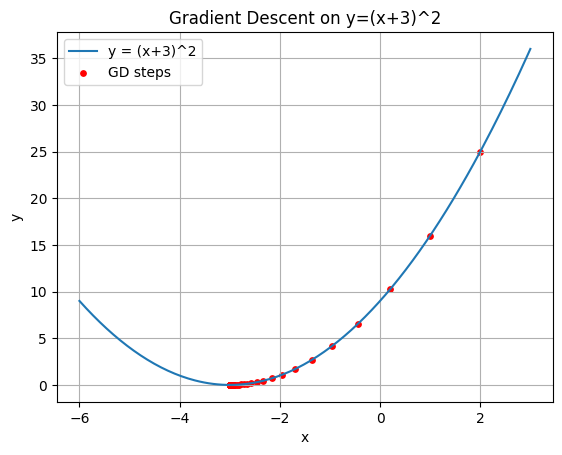

In [3]:
xs = np.linspace(-6, 3, 200)
plt.plot(xs, f(xs), label="y = (x+3)^2")
plt.scatter(history_gd, [f(h) for h in history_gd], c="red", s=15, label="GD steps")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.grid(True)
plt.title("Gradient Descent on y=(x+3)^2"); plt.show()

### Effect of the learning rate

In [4]:
for lr_ in [0.01, 0.1, 0.5, 0.9, 1.0, 1.1]:
    xv = 2.0
    for _ in range(100):
        xv = xv - lr_ * df_(xv)
    print(f"learning rate {lr_:<5} -> x after 100 steps = {xv:.4f}")

learning rate 0.01  -> x after 100 steps = -2.3369
learning rate 0.1   -> x after 100 steps = -3.0000
learning rate 0.5   -> x after 100 steps = -3.0000
learning rate 0.9   -> x after 100 steps = -3.0000
learning rate 1.0   -> x after 100 steps = 2.0000
learning rate 1.1   -> x after 100 steps = 414089869.6101


**Conclusion (Practical 4):** x converges to -3 and y to 0. A very small rate is slow, a rate of 1.0 oscillates forever, and a rate above 1 diverges.